In [1]:
import dispatch
import dispatch.select as ds
import dispatch.yt as dyt
import numpy as np
import yt as yt
import matplotlib.pyplot as pl

In [2]:
data='../data'
run = ''
iout=0
ds = dyt.open_amr(iout=iout,run=run,data=data,verbose=1,copy=True)

ValueError: could not convert string to float: '-8.3333333333333370E-002-0.41666666666666669'

In [ ]:
center = [0.,0.,0.0005]
varfield = 'density'
slc=yt.SlicePlot(ds=ds,axis="z",fields=[varfield,'magnetic_pressure'],center=center,width = ((1,'cm'),(1.0,'cm')))
#slc.set_buff_size(4096)
slc.set_cmap(varfield,"viridis")
slc.set_cmap('magnetic_pressure','RdBu_r')
#slc.annotate_grids()
#slc.annotate_timestamp()
slc.show()

# Reference


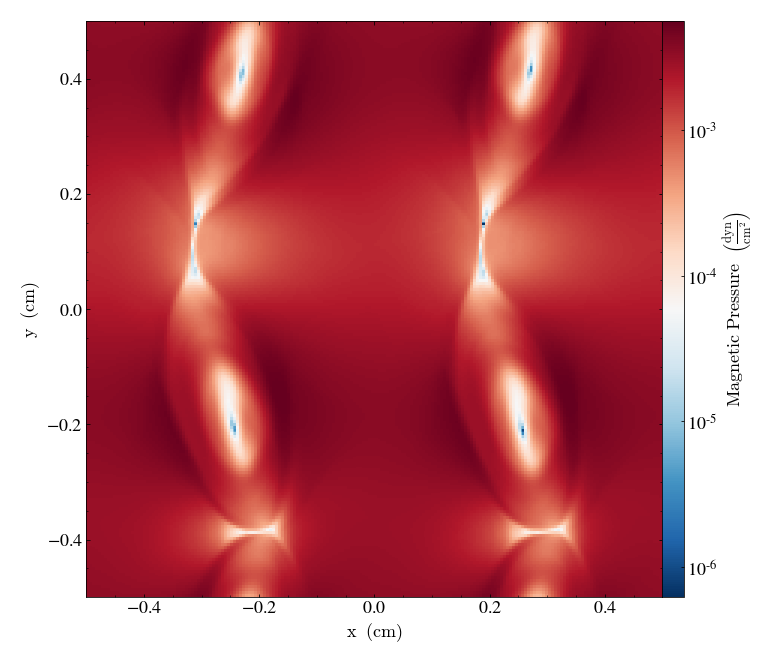
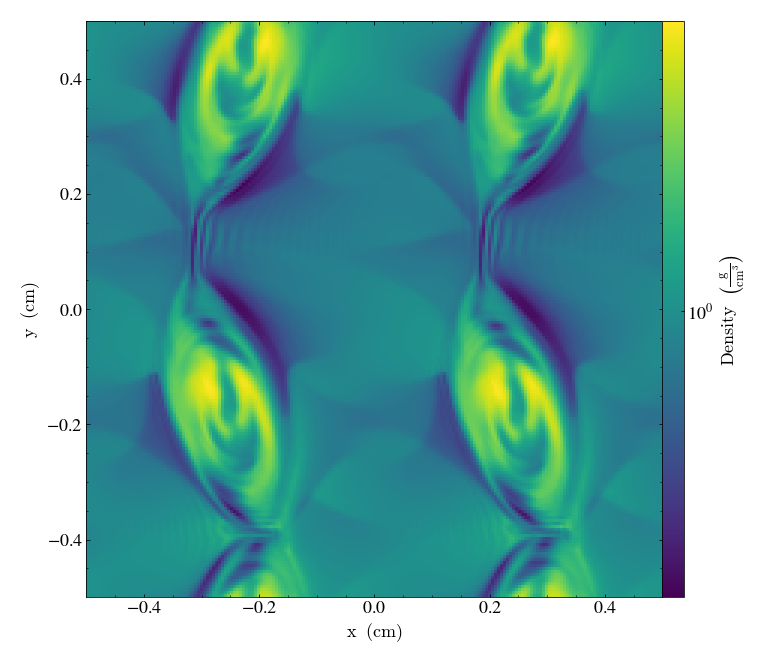

In [4]:
slc.show()

# Scratch

In [2]:
import dispatch.graphics as dg
def im3(pp,iv,vmin,vmax,varname): #,ylim0=0,ylim1=3):
    #pl.xlim(0,1)#; pl.ylim(ylim0,ylim1)
    num_patches = len(pp.patches)
    n=pp.patches[0].n
    g=pp.patches[0].ng
    m=int(n.max()/2 -1)
    dim = pp.cartesian.dims
    pos_arr = np.zeros([int(dim[0]),int(dim[1]),int(dim[2])])
    patch_arr = np.zeros([np.shape(pos_arr)[0]*n[0], np.shape(pos_arr)[1]*n[1], np.shape(pos_arr)[2]*n[2]])
    for ip in range(num_patches):
        p = pp.patches[ip]
        pos = (p.position-pp.cartesian.origin)*pp.cartesian.dims
        position = [int(pos[0]), int(pos[1]), int(pos[2])]
        pos_arr[position[0], position[1], position[2]] = p.id
        if (iv==10):
            data= (p.var(5)**2+p.var(6)**2+p.var(7)**2)/(8*np.pi)
            varname='magnetic pressure'
        elif (iv==11):
            data= (p.var(4)*(s.gamma-1.0))
            varname='gas pressure'
        else:
            data=p.data[iv] if hasattr(p,'data') else p.var(iv)
        no_gz=data[g[0]:-g[0],g[1]:-g[1],g[2]:-g[2]]
        no_gz=data
        #no_gz=data[g[0]:-g[0],g[1]:-g[1],g[2]:-g[2]]
        patch_arr[position[0]*n[0]:position[0]*n[0]+n[0],position[1]*n[1]:position[1]*n[1]+n[1],position[2]*n[2]:position[2]*n[2]+n[2]] = no_gz
      #print(pos_arr)
      #print(np.shape(patch_arr.transpose()))
      #final = np.sum(patch_arr,axis=1).transpose() #.transpose().reshape(n[0]*3,n[0]*3)
    if (n[2]==1):
        final = patch_arr[:,:,0].transpose()
    elif (n[0]==1):
        final = patch_arr[0,:,:].transpose()
    elif (n[1]==1):
        final = patch_arr[:,0,:].transpose()
    pl.imshow(final, cmap='viridis')
    pl.title(varname); 
    pl.colorbar(shrink=0.1)
def getvar(pp,iv): #,ylim0=0,ylim1=3):
    #pl.xlim(0,1)#; pl.ylim(ylim0,ylim1)
    num_patches = len(pp.patches)
    n=pp.patches[0].n
    n[2]=1
    g=pp.patches[0].ng
    m=int(n[1]/2 -1)
    pos_arr = np.zeros([int(pp.cartesian.dims[0]),int(pp.cartesian.dims[1]),int(pp.cartesian.dims[2])])
    patch_arr = np.zeros([np.shape(pos_arr)[0]*n[0], np.shape(pos_arr)[1]*n[1], np.shape(pos_arr)[2]*n[2]])
    for ip in range(num_patches):
        p = pp.patches[ip]
        position = [int((p.position[0]-pp.cartesian.origin[0])*pp.cartesian.dims[0]), int((p.position[1]-pp.cartesian.origin[1])*pp.cartesian.dims[1]), int(p.position[2])]
        #position=[0,0,0]
        #print (ip,position,p.position)
        pos_arr[position[0], position[1], position[2]] = p.id
        if (iv==10):
            data= (p.var(5)**2+p.var(6)**2+p.var(7)**2)/(8*np.pi)
            varname='magnetic pressure'
        elif (iv==11):
            data= (p.var(4)*(s.gamma-1.0))
            varname='gas pressure'
        else:
            data=p.data[iv] if hasattr(p,'data') else p.var(iv)
        #no_gz=data[g[0]:-g[0],g[1]:-g[1],:]
        no_gz=data
        #no_gz=data[g[0]:-g[0],g[1]:-g[1],g[2]:-g[2]]
        patch_arr[position[0]*n[0]:position[0]*n[0]+n[0],position[1]*n[1]:position[1]*n[1]+n[1],position[2]*n[2]:position[2]*n[2]+n[2]] = no_gz
    #print(pos_arr)
    #print(np.shape(patch_arr.transpose()))
    #final = np.sum(patch_arr,axis=1).transpose() #.transpose().reshape(n[0]*3,n[0]*3)
    final = patch_arr[:,:,0].transpose()
    return final

KeyError: 0

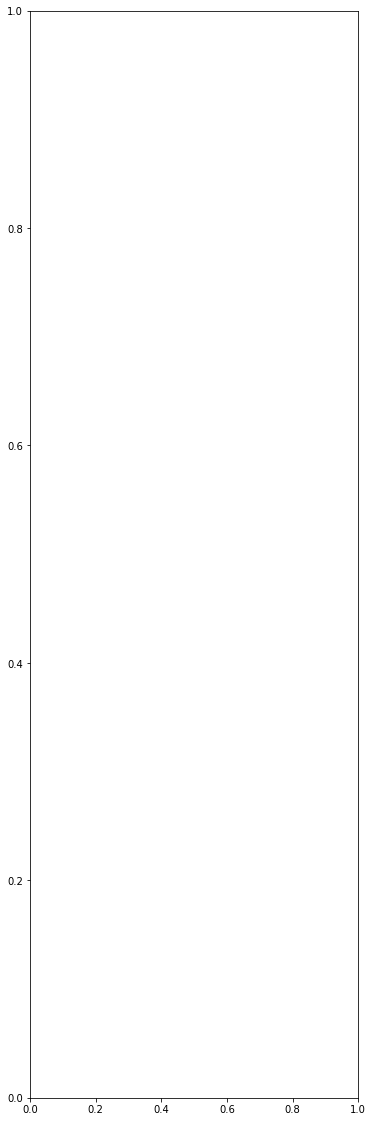

In [4]:
run=''
data='../data'
iout=7
s=dispatch.snapshot(iout=iout,run=run,data=data, copy=True,verbose=0)
pl.figure(1, figsize=(20,20))
pl.clf()
        #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
        #for ip in range(num_patches):
        #    pp = ss[it].patches[ip]
        #    #density = pp.data[0]
pl.subplot(1,3,1); im3(s, 0, 470, 530 ,'d')#,ylim0,ylim1)
pl.subplot(1,3,2); im3(s, 6, -.20, +.20 ,'e' )
        #pl.subplot(1,4,2); im3(ss[it], 7, 0.00, 0.08, 'bz')#,ylim0,ylim1)
pl.subplot(1,3,3); im3(s, 10, -.20, +.20, 'bz')#,ylim0,ylim1)
#pl.subplot(2,2,4); im3(s, 11, -.20, +.20, 'by')#,ylim0,ylim1)
pl.tight_layout()
pl.draw()
pl.pause(0.001)
pl.show()

In [ ]:
bx=getvar(s,5)
by=getvar(s,6)
bs=getvar(s,10)
import matplotlib.gridspec as gridspec
fig = pl.figure(figsize=(7, 9))
gs = gridspec.GridSpec(nrows=1, ncols=1, height_ratios=[1])
ax = fig.add_subplot(gs[0,0])
N=bx.shape[0]
print (bx.shape, bs.shape)
x = y = np.linspace(-0.5,0.5,N,endpoint=True)
yv,xv = np.mgrid[-0.5:0.5:160j, -0.5:0.5:160j]
ax.set_title('Magnetic streamlines')
ax.set_xlabel('x-axis')
ax.set_ylabel('y-axis')
ax.streamplot(
   xv,
   yv,
   bx,
   by,
   density=[2.0,3.0],
   color='black',
   linewidth=(bs/bs.max()) * 2.0)

ax.set_xlim([-0.5,0.5])
ax.set_ylim([-0.5,0.5])
ax.set_aspect('equal')
ax.grid(False)
        #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
        #for ip in range(num_patches):
        #    pp = ss[it].patches[ip]
        #    #density = pp.data[0]
pl.tight_layout()
pl.show()

In [ ]:
pl.figure(1, figsize=(20,20))
for iout in range(0,333):
    #iout=998
    s=dispatch.snapshot(iout=iout,run=run,data=data, copy=True,verbose=0)
    pl.clf()
            #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
            #for ip in range(num_patches):
            #    pp = ss[it].patches[ip]
            #    #density = pp.data[0]
    pl.subplot(1,3,1); im3(s, 0, 470, 530 ,'d')#,ylim0,ylim1)
    pl.subplot(1,3,2); im3(s, 6, -.20, +.20 ,'e' )
            #pl.subplot(1,4,2); im3(ss[it], 7, 0.00, 0.08, 'bz')#,ylim0,ylim1)
    pl.subplot(1,3,3); im3(s, 11, -.20, +.20, 'bx')#,ylim0,ylim1)
    #pl.subplot(2,2,4); im3(s, 11, -.20, +.20, 'by')#,ylim0,ylim1)
    pl.tight_layout()
    pl.draw()
    #pl.pause(0.01)
    #pl.show()
    pl.savefig("{}/{:03d}".format('figs',iout))

In [ ]:
import matplotlib.gridspec as gridspec
for iout in range(0,332):
    print ('working on ', iout)
    s=dispatch.snapshot(iout=iout,run=run,data=data, copy=True,verbose=0)
    bx=getvar(s,5)
    by=getvar(s,6)
    bs=getvar(s,10)
    pl.clf()
    fig = pl.figure(figsize=(7, 9))
    gs = gridspec.GridSpec(nrows=1, ncols=1, height_ratios=[1])
    ax = fig.add_subplot(gs[0,0])
    N=bx.shape[0]
    x = y = np.linspace(-0.5,0.5,N,endpoint=True)
    yv,xv = np.mgrid[-0.5:0.5:224j, -0.5:0.5:224j]
    ax.set_title('Magnetic streamlines')
    ax.set_xlabel('x-axis')
    ax.set_ylabel('y-axis')
    ax.streamplot(
       xv,
       yv,
       bx,
       by,
       density=[2.0,3.0],
       color='black',
       linewidth=(bs/bs.max()) * 2.0)

    ax.set_xlim([-0.5,0.5])
    ax.set_ylim([-0.5,0.5])
    ax.set_aspect('equal')
    ax.grid(False)
            #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
            #for ip in range(num_patches):
            #    pp = ss[it].patches[ip]
            #    #density = pp.data[0]
    pl.tight_layout()
    pl.savefig("{}/{:03d}".format('contour',iout))

In [36]:
s.ng

[8, 0, 8]